In [11]:
import sys
import os

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

import numpy as np
import pandas as pd

from utils.indicators import *
from utils.engine import *

import lightgbm as lgb
from sklearn.metrics import precision_score, recall_score, classification_report
import matplotlib.pyplot as plt

# ============================================================================
# CONFIG
# ============================================================================
LOOKAHEAD_SECONDS   = 240     # how far forward we check if the barrier was hit
BARRIER_MULTIPLIER  = 1.0     # profit/stop barrier = multiplier * horizon-scaled vol
RSI_FILTER_COLUMN   = 'rsi_14'
RSI_FILTER_THRESHOLD = 30
EPS                 = 1e-9    # guards against division by zero

# --- Chronological Validation Settings ---
N_RANDOM_SAMPLES    = 15      # Number of sequential walk-forward folds to test
TEST_BLOCK_SIZE     = 10000   # Number of rows per test chunk
EMBARGO_SECONDS     = LOOKAHEAD_SECONDS

# --- 3-Class Label Encoding ---
# WIN     = profit barrier was reached AND the stop barrier was never breached
# LOSS    = stop barrier was breached (regardless of whether price also
#           technically touched the profit barrier somewhere in the window —
#           this mirrors the original binary logic, which also called that
#           case a "0" since it can't tell barrier-touch order from mfe/mae alone)
# TIMEOUT = neither barrier was breached before the lookahead window ran out
LABEL_LOSS    = 0
LABEL_TIMEOUT = 1
LABEL_WIN     = 2
CLASS_NAMES   = {LABEL_LOSS: 'LOSS', LABEL_TIMEOUT: 'TIMEOUT', LABEL_WIN: 'WIN'}


# ============================================================================
# STEP 1 — Per-session feature pipeline
# ============================================================================
def load_and_build_state_space(orderbook_path, trades_path, session_id):
    df_orderbook = pd.read_csv(orderbook_path)
    df_trades = pd.read_csv(trades_path)

    df_orderbook['datetime'] = pd.to_datetime(df_orderbook['timestamp'], unit='ms')
    df_trades['datetime'] = pd.to_datetime(df_trades['timestamp'], unit='ms')

    df_orderbook = df_orderbook.set_index('datetime').sort_index()
    df_trades = df_trades.set_index('datetime').sort_index()

    df_orderbook['mid_price'] = (df_orderbook['bid_price'] + df_orderbook['ask_price']) / 2

    df_ob_1m = df_orderbook.resample('1min').agg({
        'mid_price': ['first', 'max', 'min', 'last'],
        'bid_price': 'last',
        'ask_price': 'last',
        'bid_amount': 'sum',
        'ask_amount': 'sum',
    })
    df_ob_1m.columns = ['open', 'high', 'low', 'close', 'bid_price', 'ask_price', 'bid_amount', 'ask_amount']
    df_ob_1m['spread'] = df_ob_1m['ask_price'] - df_ob_1m['bid_price']

    df_trades['buy_vol'] = df_trades['amount'].where(df_trades['side'] == 'buy', 0)
    df_trades['sell_vol'] = df_trades['amount'].where(df_trades['side'] == 'sell', 0)

    df_micro = df_trades.resample('1s').agg({
        'price': 'last',
        'buy_vol': 'sum',
        'sell_vol': 'sum'
    }).ffill()

    df_micro['micro_OFI'] = df_micro['buy_vol'] - df_micro['sell_vol']
    df_micro['micro_CVD'] = df_micro['micro_OFI'].rolling(10).sum()

    df_trades_1m = df_trades.resample('1min').agg({
        'price': ['first', 'max', 'min', 'last', 'count'],
        'amount': 'sum',
        'buy_vol': ['sum', 'max'],
        'sell_vol': ['sum', 'max']
    })
    df_trades_1m.columns = ['open', 'high', 'low', 'close', 'num_trades', 'volume',
                             'agg_buyer', 'largest_buyer', 'agg_seller', 'largest_seller']
    df_trades_1m = df_trades_1m.dropna(subset=['close'])

    df_price_1m = pd.DataFrame({
        'open': df_ob_1m['open'],
        'high': df_ob_1m['high'],
        'low': df_ob_1m['low'],
        'close': df_ob_1m['close'],
        'largest_buyer': df_trades_1m['largest_buyer'] * 100 / (df_trades_1m['volume'] + EPS),
        'largest_seller': df_trades_1m['largest_seller'] * 100 / (df_trades_1m['volume'] + EPS),
        'OFI_LOB': 100 * (df_ob_1m['bid_amount'] - df_ob_1m['ask_amount']) / (df_ob_1m['bid_amount'] + df_ob_1m['ask_amount'] + EPS),
        'OFI_AGG': 100 * (df_trades_1m['agg_buyer'] - df_trades_1m['agg_seller']) / (df_trades_1m['agg_buyer'] + df_trades_1m['agg_seller'] + EPS),
        'CVD_raw': calculate_cvd(df_trades_1m['agg_buyer'], df_trades_1m['agg_seller']),
        'candle_type': abs(df_ob_1m['close'] - df_ob_1m['open']) / (abs(df_ob_1m['high'] - df_ob_1m['low']) + EPS),
        'candle_size': (df_ob_1m['high'] - df_ob_1m['low']) / ((df_ob_1m['high'] - df_ob_1m['low']).rolling(14).mean() + EPS),
    })

    cvd_delta = df_price_1m['CVD_raw'].diff()
    df_price_1m['CVD_z'] = (cvd_delta - cvd_delta.rolling(60).mean()) / (cvd_delta.rolling(60).std() + EPS)
    df_price_1m = df_price_1m.drop(columns=['CVD_raw'])

    price_clean = np.asarray(df_price_1m['close'], dtype=float)
    diffs = np.diff(price_clean)

    def _pad_front(arr, target_len):
        out = np.full(target_len, np.nan)
        out[-len(arr):] = arr
        return out

    df_price_1m['rsi_2'] = _pad_front(get_wilders_rsi(diffs, 2), len(df_price_1m))
    rsi_14_raw = get_wilders_rsi(diffs, 14)
    df_price_1m['rsi_14'] = _pad_front(rsi_14_raw, len(df_price_1m))
    df_price_1m['sma_14'] = _pad_front(sma(rsi_14_raw, 14), len(df_price_1m))

    # FIXED: Lag BOTH 1s micro features AND 1m macro features to eliminate information leakage
    df_micro_shifted = df_micro.shift(1)
    df_macro_shifted = df_price_1m.shift(1)

    df_state_space = df_micro_shifted.join(df_macro_shifted, how='left').ffill()
    df_state_space = df_state_space.dropna()
    df_state_space['session_id'] = session_id

    return df_state_space


# ============================================================================
# STEP 2 — Build combined state space from all sessions
# ============================================================================

session_0 = load_and_build_state_space(
    "./csv/BTCUSDT_orderbook.csv", "./csv/BTCUSDT_trades.csv", session_id=0
)
session_1 = load_and_build_state_space(
    "./csv/BTCUSDT_orderbook_2.csv", "./csv/BTCUSDT_trades_2.csv", session_id=1
)
session_2 = load_and_build_state_space(
    "./csv/BTCUSDT_orderbook_3.csv", "./csv/BTCUSDT_trades_3.csv", session_id=1
)

df_state_space = pd.concat([session_0, session_1, session_2]).sort_index()

#df_state_space = load_and_build_state_space("./csv/XAUTUSDT_orderbook.csv", "./csv/XAUTUSDT_trades.csv", 0)

# ============================================================================
# STEP 3 — Barrier labeling (Preserving paths for exact backtesting)
# ============================================================================
def add_barrier_labels(df, lookahead_seconds=LOOKAHEAD_SECONDS, barrier_mult=BARRIER_MULTIPLIER):
    labeled = []
    for _, g in df.groupby('session_id', sort=False):
        g = g.copy()
        ret_std_1s = g['price'].pct_change().rolling(window=100).std()
        horizon_std = ret_std_1s * np.sqrt(lookahead_seconds)

        g['profit_barrier'] = horizon_std * barrier_mult
        g['stop_barrier'] = horizon_std * barrier_mult

        forward_max = (g['price'].iloc[::-1]
                       .rolling(window=lookahead_seconds, min_periods=lookahead_seconds)
                       .max().iloc[::-1])
        forward_min = (g['price'].iloc[::-1]
                       .rolling(window=lookahead_seconds, min_periods=lookahead_seconds)
                       .min().iloc[::-1])

        # Added to capture absolute path deviations & terminal returns accurately
        forward_close = g['price'].shift(-lookahead_seconds)

        g['mfe'] = (forward_max - g['price']) / g['price']
        g['mae'] = (g['price'] - forward_min) / g['price']
        g['terminal_ret'] = (forward_close - g['price']) / g['price']

        valid = g['profit_barrier'].notna() & forward_max.notna() & forward_min.notna()

        # Same underlying comparisons as before, just split into three
        # mutually-exclusive outcomes instead of collapsing "loss" and
        # "timeout" together into a single 0 class.
        is_win = (g['mfe'] >= g['profit_barrier']) & (g['mae'] < g['stop_barrier'])
        is_loss = (g['mae'] >= g['stop_barrier'])
        # anything left over (neither barrier breached inside the window) is a timeout

        g['target'] = np.nan
        g.loc[valid, 'target'] = np.select(
            [is_win[valid], is_loss[valid]],
            [LABEL_WIN, LABEL_LOSS],
            default=LABEL_TIMEOUT
        )
        labeled.append(g)

    out = pd.concat(labeled)
    out = out.dropna(subset=['target'])
    out['target'] = out['target'].astype(int)
    return out

df_state_space = add_barrier_labels(df_state_space)

label_counts = df_state_space['target'].map(CLASS_NAMES).value_counts()
print(f"Label distribution (full dataset): {label_counts.to_dict()}")

df_training_zone = df_state_space[df_state_space[RSI_FILTER_COLUMN] < RSI_FILTER_THRESHOLD]
print(f"Total rows in hunting zone: {len(df_training_zone)}")
print(f"Label distribution (hunting zone): {df_training_zone['target'].map(CLASS_NAMES).value_counts().to_dict()}")


# ============================================================================
# STEP 4 — Features / target configuration
# ============================================================================
# FIXED: Explicitly added backtest telemetry path variables into the training drop list
drop_cols = ['target', 'price', 'open', 'high', 'low', 'close',
             'profit_barrier', 'stop_barrier', 'session_id', 'mfe', 'mae', 'terminal_ret']
features = [c for c in df_training_zone.columns if c not in drop_cols]

X = df_training_zone[features]
y = df_training_zone['target']


# ============================================================================
# STEP 5 — Purged Chronological Walk-Forward Splitting
# ============================================================================
def purged_chronological_splits(index, n_samples, block_size, horizon_seconds, embargo_seconds=0):
    n = len(index)
    horizon = pd.Timedelta(seconds=horizon_seconds)
    min_initial_train = int(n * 0.35)
    available_test_run = n - min_initial_train - block_size

    if available_test_run <= 0:
        raise ValueError("The dataset length is too narrow for this test configuration block size.")

    step_intervals = available_test_run // n_samples

    for fold in range(n_samples):
        start_idx = min_initial_train + (fold * step_intervals)
        test_idx = np.arange(start_idx, start_idx + block_size)
        test_start_time = index[test_idx[0]]

        possible_train_idx = np.arange(0, start_idx)
        train_times = index[possible_train_idx]

        purge_mask = (train_times + horizon >= test_start_time)
        train_idx = possible_train_idx[~purge_mask]

        n_purged = len(possible_train_idx) - len(train_idx)
        yield train_idx, test_idx, n_purged

splitter = purged_chronological_splits(
    X.index,
    n_samples=N_RANDOM_SAMPLES,
    block_size=TEST_BLOCK_SIZE,
    horizon_seconds=LOOKAHEAD_SECONDS,
    embargo_seconds=EMBARGO_SECONDS
)

print(f"\n--- Starting {N_RANDOM_SAMPLES} Chronological Walk-Forward Validation Folds (Size: {TEST_BLOCK_SIZE}) ---")

thresholds_to_track = np.arange(0.50, 0.96, 0.05)
fold_metrics = {t: {'precisions': [], 'trades': []} for t in thresholds_to_track}
fold_importances = []

for fold, (train_idx, test_idx, n_purged) in enumerate(splitter, start=1):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    if len(X_train) == 0 or y_train.nunique() < 2:
        print(f"Fold {fold} | skipped — invalid training data distribution.")
        continue

    # scale_pos_weight is a binary-only LightGBM knob, so imbalance across the
    # three classes (LOSS / TIMEOUT / WIN) is handled with class_weight='balanced'
    # instead — the multiclass equivalent of the original neg_pos_ratio reweighting.
    clf = lgb.LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=5,
        num_leaves=31,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1,
        verbose=-1
    )

    clf.fit(X_train, y_train)

    if LABEL_WIN not in clf.classes_:
        print(f"Fold {fold} | skipped scoring — no WIN samples present in this fold's training data.")
        continue

    # predict_proba now returns one column per class present in this fold;
    # we pull out the WIN column, which is the direct multiclass analogue of
    # the old binary predict_proba(...)[:, 1] "probability of a winning trade".
    win_idx = list(clf.classes_).index(LABEL_WIN)
    y_proba = clf.predict_proba(X_test)[:, win_idx]
    y_test_is_win = (y_test == LABEL_WIN).astype(int)

    for t in thresholds_to_track:
        preds = (y_proba >= t).astype(int)
        prec = precision_score(y_test_is_win, preds, zero_division=0)
        num_trades = int(preds.sum())

        if num_trades > 0:
            fold_metrics[t]['precisions'].append(prec)
        fold_metrics[t]['trades'].append(num_trades)

    fold_importances.append(clf.feature_importances_)
    print(f"Fold {fold:02d} | Train Rows: {len(X_train):<6} | Tested on forward {TEST_BLOCK_SIZE} rows. Purged: {n_purged}")


# ============================================================================
# STEP 6 — Threshold Fluctuation Reporting
# ============================================================================
print("\n--- Edge Stability Across Chronological Windows (Honest Analysis, WIN class) ---")
print("-" * 75)
print(f"{'Threshold':<10} | {'Mean Prec':<11} | {'Std Dev (Fluct)':<16} | {'Avg Trades per Block'}")
print("-" * 75)

for t in thresholds_to_track:
    prec_array = np.array(fold_metrics[t]['precisions'])
    trades_array = np.array(fold_metrics[t]['trades'])

    if len(prec_array) > 0:
        mean_prec = np.mean(prec_array)
        std_prec = np.std(prec_array)
        mean_trades = np.mean(trades_array)

        print(f">= {t*100:>4.1f}%   | {mean_prec:>9.2%}   | ± {std_prec:<13.2%} | {mean_trades:>6.1f}")
    else:
        print(f">= {t*100:>4.1f}%   | No trades fired in any test block.")

print("-" * 75)

if fold_importances:
    imp_df = pd.DataFrame(fold_importances, columns=features)
    imp_summary = pd.DataFrame({
        'mean_importance': imp_df.mean(),
        'std_importance': imp_df.std()
    }).sort_values('mean_importance', ascending=False)

    print("\n--- Top 10 Feature Importance Stability ---")
    print(imp_summary.head(10))

Label distribution (full dataset): {'TIMEOUT': 440713, 'LOSS': 327235, 'WIN': 122991}
Total rows in hunting zone: 239940
Label distribution (hunting zone): {'TIMEOUT': 126186, 'LOSS': 108570, 'WIN': 5184}

--- Starting 15 Chronological Walk-Forward Validation Folds (Size: 10000) ---
Fold 01 | Train Rows: 83739  | Tested on forward 10000 rows. Purged: 240
Fold 02 | Train Rows: 93469  | Tested on forward 10000 rows. Purged: 240
Fold 03 | Train Rows: 103199 | Tested on forward 10000 rows. Purged: 240
Fold 04 | Train Rows: 112929 | Tested on forward 10000 rows. Purged: 240
Fold 05 | Train Rows: 122659 | Tested on forward 10000 rows. Purged: 240
Fold 06 | Train Rows: 132389 | Tested on forward 10000 rows. Purged: 240
Fold 07 | Train Rows: 142119 | Tested on forward 10000 rows. Purged: 240
Fold 08 | Train Rows: 151849 | Tested on forward 10000 rows. Purged: 240
Fold 09 | Train Rows: 161640 | Tested on forward 10000 rows. Purged: 179
Fold 10 | Train Rows: 171309 | Tested on forward 10000 rows

# Patch for ml-state code by AI
Integrate random splitting of data to ensure the code truly works and there is no overfitting problem. How we test the stability of machine learning algo:
- Run on large-sample sized splits (20k). Measure Mean Precision of trades across sample size then get Std Dev to get flucutation of performance in machine learning algo.
- Deduce based on expectancy formula if strtaegy is profitable or not. Further validation by changing sample size, switching tickers, etc.

# Conclusion (20k samples)
![performance](./image/img_12.png)

With condition 2RR, trading on 85%-95% shows a very stable edge.
- Average no of trades: 5.67 trades per hour
- 85.0%: 52.36% * 2RR - 47.64% = 0.5708RR
- Worst condition: (52.36% - 22.98%) * 2RR - (100% - 52.36% + 22.98%) = 0.5876 - 0.7062 = -0.1186RR
- Using assumption that it is a normal distribution, 65% of the time, the model performs reasonably well and generally has a positive expectancy. However there is a 5% chance that the model experiences severe underperformance (2x stdev)

# Conclusion (10k samples split)
![Performance](./image/img_13.png)

With condition 2RR, trading on 85%-95% shows a very stable edge.
- Average no of trades: 3.348 trades per hour
- 85.0%: 62.37% * 2RR - 37.63% = 0.8711RR
- Worst condition: (62.37% - 21.44%) * 2RR - (100% - 62.37% + 21.44%) = 0.8186 - 0.5907 = 0.2279RR
- Using assumption that it is a normal distribution, 65% of the time, the model performs exceptionally well and generally has a positive expectancy even when the market is 1stdev worse. For the strategy to hit breakeven, it should hit the 1.38x stdev area.

Nevermind ignore this conclusion for now. realized lookahead bias

Label distribution (full dataset): {'LOSS': 97197, 'WIN': 41282}
Total rows in hunting zone: 42720
Label distribution (hunting zone): {'LOSS': 40762, 'WIN': 1958}

--- Starting 15 Chronological Walk-Forward Validation Folds (Size: 10000) ---
Fold 01 | Train Rows: 14471  | Tested on forward 10000 rows. Purged: 480
Fold 02 | Train Rows: 15655  | Tested on forward 10000 rows. Purged: 480
Fold 03 | Train Rows: 16839  | Tested on forward 10000 rows. Purged: 480
Fold 04 | Train Rows: 18023  | Tested on forward 10000 rows. Purged: 480
Fold 05 | Train Rows: 19207  | Tested on forward 10000 rows. Purged: 480
Fold 06 | Train Rows: 20391  | Tested on forward 10000 rows. Purged: 480
Fold 07 | Train Rows: 21575  | Tested on forward 10000 rows. Purged: 480
Fold 08 | Train Rows: 22759  | Tested on forward 10000 rows. Purged: 480
Fold 09 | Train Rows: 23943  | Tested on forward 10000 rows. Purged: 480
Fold 10 | Train Rows: 25127  | Tested on forward 10000 rows. Purged: 480
Fold 11 | Train Rows: 26311 

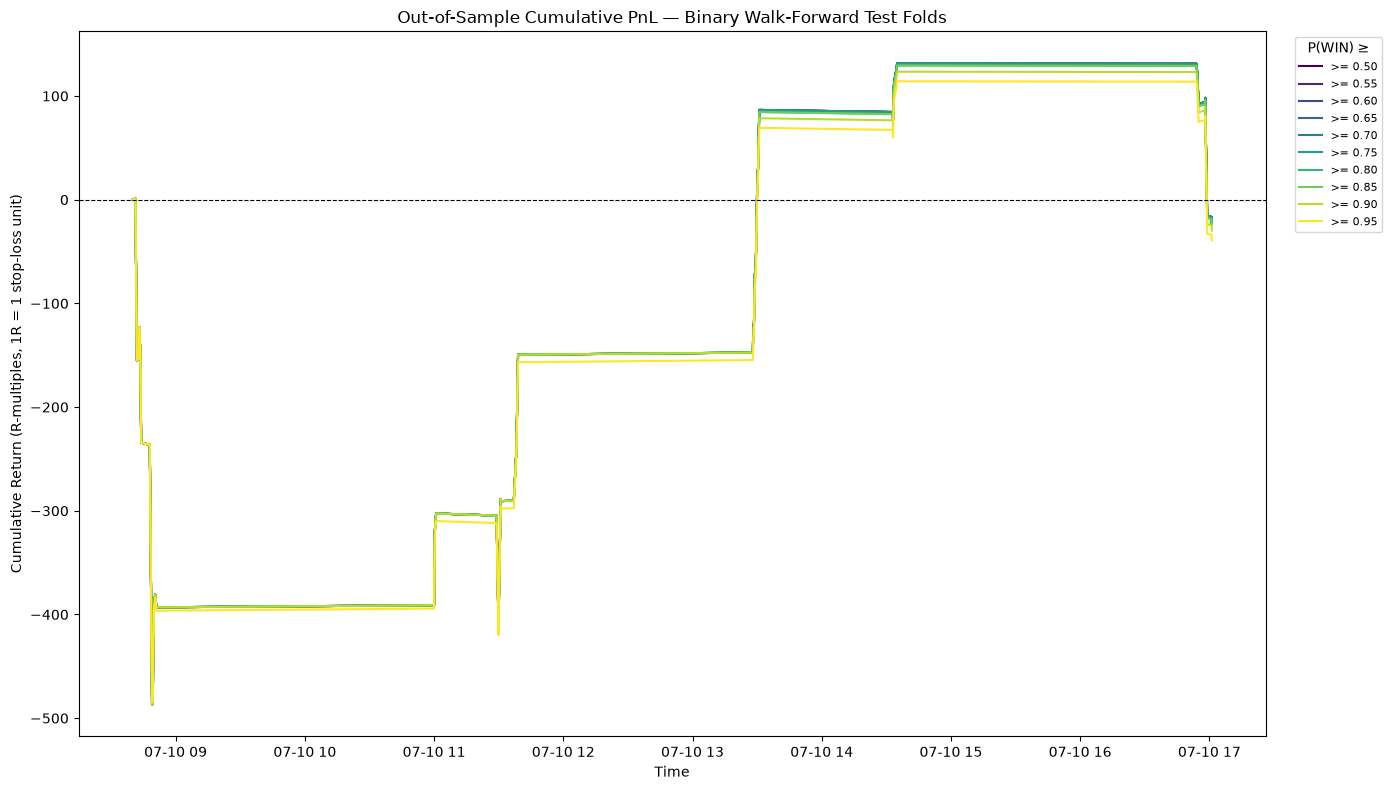


Saved chart to pnl_walkforward.png

SUMMARY
Sequential (order-aware) binary barrier labels, full dataset: {'LOSS': 97197, 'WIN': 41282}
Hunting zone (rsi_14 < 30) rows: 42720
  LOSS     class precision (argmax): 99.78% ± 0.69% across folds
  WIN      class precision (argmax): 7.35% ± 18.93% across folds
Best mean out-of-sample RR across folds: 0.59 at P(WIN) >= 0.50
  P(WIN) >= 0.50: 1280 trades, cumulative -21.85R out-of-sample
  P(WIN) >= 0.55: 1280 trades, cumulative -21.85R out-of-sample
  P(WIN) >= 0.60: 1280 trades, cumulative -21.85R out-of-sample
  P(WIN) >= 0.65: 1280 trades, cumulative -21.85R out-of-sample
  P(WIN) >= 0.70: 1280 trades, cumulative -21.85R out-of-sample
  P(WIN) >= 0.75: 1280 trades, cumulative -21.85R out-of-sample
  P(WIN) >= 0.80: 1279 trades, cumulative -23.85R out-of-sample
  P(WIN) >= 0.85: 1279 trades, cumulative -23.85R out-of-sample
  P(WIN) >= 0.90: 1276 trades, cumulative -29.85R out-of-sample
  P(WIN) >= 0.95: 1267 trades, cumulative -39.10R out-

In [ ]:
import sys
import os

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

import numpy as np
import pandas as pd
from numpy.lib.stride_tricks import sliding_window_view

from utils.indicators import *
from utils.engine import *

import lightgbm as lgb
from sklearn.metrics import precision_score, recall_score, classification_report
import matplotlib.pyplot as plt

# ============================================================================
# CONFIG
# ============================================================================
LOOKAHEAD_SECONDS    = 240     # how far forward we walk the price path looking for a barrier touch
BARRIER_MULTIPLIER   = 1.0     # profit/stop barrier = multiplier * horizon-scaled vol
RSI_FILTER_COLUMN    = 'rsi_14'
RSI_FILTER_THRESHOLD = 30
EPS                  = 1e-9    # guards against division by zero
BARRIER_CHUNK_SIZE   = 50_000  # rows processed per chunk in the vectorized barrier walk (memory control)

# --- Chronological Validation Settings ---
N_RANDOM_SAMPLES    = 15      # Number of sequential walk-forward folds to test
TEST_BLOCK_SIZE     = 10000   # Number of rows per test chunk
EMBARGO_SECONDS      = LOOKAHEAD_SECONDS

# --- 2-Class Binary Label Encoding ---
# WIN  = Profit barrier touched FIRST, OR timeout occurred with price > entry
# LOSS = Stop barrier touched FIRST, OR timeout occurred with price <= entry
LABEL_LOSS    = 0
LABEL_WIN     = 1
CLASS_NAMES   = {LABEL_LOSS: 'LOSS', LABEL_WIN: 'WIN'}


# ============================================================================
# STEP 1 — Per-session feature pipeline
# ============================================================================
def load_and_build_state_space(orderbook_path, trades_path, session_id):
    df_orderbook = pd.read_csv(orderbook_path)
    df_trades = pd.read_csv(trades_path)

    df_orderbook['datetime'] = pd.to_datetime(df_orderbook['timestamp'], unit='ms')
    df_trades['datetime'] = pd.to_datetime(df_trades['timestamp'], unit='ms')

    df_orderbook = df_orderbook.set_index('datetime').sort_index()
    df_trades = df_trades.set_index('datetime').sort_index()

    df_orderbook['mid_price'] = (df_orderbook['bid_price'] + df_orderbook['ask_price']) / 2

    df_ob_1m = df_orderbook.resample('1min').agg({
        'mid_price': ['first', 'max', 'min', 'last'],
        'bid_price': 'last',
        'ask_price': 'last',
        'bid_amount': 'sum',
        'ask_amount': 'sum',
    })
    df_ob_1m.columns = ['open', 'high', 'low', 'close', 'bid_price', 'ask_price', 'bid_amount', 'ask_amount']
    df_ob_1m['spread'] = df_ob_1m['ask_price'] - df_ob_1m['bid_price']

    df_trades['buy_vol'] = df_trades['amount'].where(df_trades['side'] == 'buy', 0)
    df_trades['sell_vol'] = df_trades['amount'].where(df_trades['side'] == 'sell', 0)

    df_micro = df_trades.resample('1s').agg({
        'price': 'last',
        'buy_vol': 'sum',
        'sell_vol': 'sum'
    }).ffill()

    df_micro['micro_OFI'] = df_micro['buy_vol'] - df_micro['sell_vol']
    df_micro['micro_CVD'] = df_micro['micro_OFI'].rolling(10).sum()

    df_trades_1m = df_trades.resample('1min').agg({
        'price': ['first', 'max', 'min', 'last', 'count'],
        'amount': 'sum',
        'buy_vol': ['sum', 'max'],
        'sell_vol': ['sum', 'max']
    })
    df_trades_1m.columns = ['open', 'high', 'low', 'close', 'num_trades', 'volume',
                             'agg_buyer', 'largest_buyer', 'agg_seller', 'largest_seller']
    df_trades_1m = df_trades_1m.dropna(subset=['close'])

    df_price_1m = pd.DataFrame({
        'open': df_ob_1m['open'],
        'high': df_ob_1m['high'],
        'low': df_ob_1m['low'],
        'close': df_ob_1m['close'],
        'largest_buyer': df_trades_1m['largest_buyer'] * 100 / (df_trades_1m['volume'] + EPS),
        'largest_seller': df_trades_1m['largest_seller'] * 100 / (df_trades_1m['volume'] + EPS),
        'OFI_LOB': 100 * (df_ob_1m['bid_amount'] - df_ob_1m['ask_amount']) / (df_ob_1m['bid_amount'] + df_ob_1m['ask_amount'] + EPS),
        'OFI_AGG': 100 * (df_trades_1m['agg_buyer'] - df_trades_1m['agg_seller']) / (df_trades_1m['agg_buyer'] + df_trades_1m['agg_seller'] + EPS),
        'CVD_raw': calculate_cvd(df_trades_1m['agg_buyer'], df_trades_1m['agg_seller']),
        'candle_type': abs(df_ob_1m['close'] - df_ob_1m['open']) / (abs(df_ob_1m['high'] - df_ob_1m['low']) + EPS),
        'candle_size': (df_ob_1m['high'] - df_ob_1m['low']) / ((df_ob_1m['high'] - df_ob_1m['low']).rolling(14).mean() + EPS),
    })

    cvd_delta = df_price_1m['CVD_raw'].diff()
    df_price_1m['CVD_z'] = (cvd_delta - cvd_delta.rolling(60).mean()) / (cvd_delta.rolling(60).std() + EPS)
    df_price_1m = df_price_1m.drop(columns=['CVD_raw'])

    price_clean = np.asarray(df_price_1m['close'], dtype=float)
    diffs = np.diff(price_clean)

    def _pad_front(arr, target_len):
        out = np.full(target_len, np.nan)
        out[-len(arr):] = arr
        return out

    df_price_1m['rsi_2'] = _pad_front(get_wilders_rsi(diffs, 2), len(df_price_1m))
    rsi_14_raw = get_wilders_rsi(diffs, 14)
    df_price_1m['rsi_14'] = _pad_front(rsi_14_raw, len(df_price_1m))
    df_price_1m['sma_14'] = _pad_front(sma(rsi_14_raw, 14), len(df_price_1m))

    df_micro_shifted = df_micro.shift(1)
    df_macro_shifted = df_price_1m.shift(1)

    df_state_space = df_micro_shifted.join(df_macro_shifted, how='left').ffill()
    df_state_space = df_state_space.dropna()
    df_state_space['session_id'] = session_id

    return df_state_space


# ============================================================================
# STEP 2 — Build combined state space from all sessions
# ============================================================================
df_state_space = load_and_build_state_space("./csv/XAUTUSDT_orderbook.csv", "./csv/XAUTUSDT_trades.csv", 0)


# ============================================================================
# STEP 3 — Barrier labeling (sequential / path-dependent binary-barrier)
# ============================================================================
def _sequential_triple_barrier(price, profit_thresh, stop_thresh, lookahead, chunk_size=BARRIER_CHUNK_SIZE):
    price = np.asarray(price, dtype=float)
    profit_thresh = np.asarray(profit_thresh, dtype=float)
    stop_thresh = np.asarray(stop_thresh, dtype=float)
    n = len(price)

    label = np.full(n, LABEL_LOSS, dtype=int)
    exit_offset = np.full(n, -1, dtype=int)
    exit_ret = np.full(n, np.nan)
    terminal_ret = np.full(n, np.nan)
    is_timeout = np.zeros(n, dtype=bool)
    valid = np.zeros(n, dtype=bool)

    usable_n = n - lookahead 
    if usable_n <= 0:
        return label, exit_offset, exit_ret, terminal_ret, is_timeout, valid

    for c0 in range(0, usable_n, chunk_size):
        c1 = min(c0 + chunk_size, usable_n)

        p0 = price[c0:c1]
        pt = profit_thresh[c0:c1]
        st = stop_thresh[c0:c1]

        upper = p0 * (1.0 + pt)
        lower = p0 * (1.0 - st)

        window = sliding_window_view(price[c0 + 1: c1 + lookahead], lookahead) 

        hit_upper = window >= upper[:, None]
        hit_lower = window <= lower[:, None]

        has_upper = hit_upper.any(axis=1)
        has_lower = hit_lower.any(axis=1)
        first_upper = np.argmax(hit_upper, axis=1) 
        first_lower = np.argmax(hit_lower, axis=1) 

        win_mask = has_upper & (~has_lower | (first_upper < first_lower))
        loss_mask = has_lower & (~has_upper | (first_lower < first_upper))
        
        # Determine timeouts and resolve them based on terminal price vs entry
        timeout_mask = ~(win_mask | loss_mask)
        timeout_win_mask = timeout_mask & (window[:, -1] > p0)
        timeout_loss_mask = timeout_mask & (window[:, -1] <= p0)

        thresholds_ok = ~np.isnan(pt) & ~np.isnan(st)

        lab = np.full(c1 - c0, LABEL_LOSS, dtype=int)
        lab[win_mask | timeout_win_mask] = LABEL_WIN
        lab[loss_mask | timeout_loss_mask] = LABEL_LOSS

        off = np.full(c1 - c0, lookahead - 1, dtype=int) 
        off[win_mask] = first_upper[win_mask]
        off[loss_mask] = first_lower[loss_mask]

        exit_price = window[np.arange(c1 - c0), off]

        label[c0:c1] = lab
        exit_offset[c0:c1] = off
        exit_ret[c0:c1] = (exit_price - p0) / p0
        terminal_ret[c0:c1] = (window[:, -1] - p0) / p0
        is_timeout[c0:c1] = timeout_mask
        valid[c0:c1] = thresholds_ok

    return label, exit_offset, exit_ret, terminal_ret, is_timeout, valid


def add_barrier_labels(df, lookahead_seconds=LOOKAHEAD_SECONDS, barrier_mult=BARRIER_MULTIPLIER):
    labeled = []
    for _, g in df.groupby('session_id', sort=False):
        g = g.copy()
        ret_std_1s = g['price'].pct_change().rolling(window=100).std()
        horizon_std = ret_std_1s * np.sqrt(lookahead_seconds)

        g['profit_barrier'] = horizon_std * barrier_mult
        g['stop_barrier'] = horizon_std * barrier_mult

        label, exit_offset, exit_ret, terminal_ret, is_timeout, valid = _sequential_triple_barrier(
            g['price'].values, g['profit_barrier'].values, g['stop_barrier'].values, lookahead_seconds
        )

        g['target'] = label
        g['bars_to_exit'] = exit_offset      
        g['exit_ret'] = exit_ret             
        g['terminal_ret'] = terminal_ret     
        g['is_timeout'] = is_timeout
        g['_valid'] = valid

        g = g[g['_valid']].drop(columns=['_valid'])
        g['target'] = g['target'].astype(int)

        labeled.append(g)

    return pd.concat(labeled)

df_state_space = add_barrier_labels(df_state_space)

label_counts = df_state_space['target'].map(CLASS_NAMES).value_counts()
print(f"Label distribution (full dataset): {label_counts.to_dict()}")

df_training_zone = df_state_space[df_state_space[RSI_FILTER_COLUMN] < RSI_FILTER_THRESHOLD]
print(f"Total rows in hunting zone: {len(df_training_zone)}")
print(f"Label distribution (hunting zone): {df_training_zone['target'].map(CLASS_NAMES).value_counts().to_dict()}")


# ============================================================================
# STEP 4 — Features / target configuration
# ============================================================================
drop_cols = ['target', 'price', 'open', 'high', 'low', 'close',
             'profit_barrier', 'stop_barrier', 'session_id',
             'bars_to_exit', 'exit_ret', 'terminal_ret', 'is_timeout']
features = [c for c in df_training_zone.columns if c not in drop_cols]

X = df_training_zone[features]
y = df_training_zone['target']

# ============================================================================
# STEP 5 — Risk-Normalized Return (R-Multiple Bookkeeping)
# ----------------------------------------------------------------------------
# Accounts for timeouts by mapping barrier hits to +/- 1.0R and timeouts to
# their exact fractional R (e.g. +0.4R or -0.2R) relative to the stop distance.
# ============================================================================
normalized_return = pd.Series(index=df_training_zone.index, dtype=float)

is_timeout = df_training_zone['is_timeout']
is_win = df_training_zone['target'] == LABEL_WIN
is_loss = df_training_zone['target'] == LABEL_LOSS

# Exact barrier hits resolve to exactly +1R or -1R
normalized_return[is_win & ~is_timeout] = 1.0
normalized_return[is_loss & ~is_timeout] = -1.0

# Timeouts resolve to their realized fractional R 
normalized_return[is_timeout] = (
    df_training_zone.loc[is_timeout, 'exit_ret'] /
    (df_training_zone.loc[is_timeout, 'stop_barrier'] + EPS)
)


# ============================================================================
# STEP 6 — Purged Chronological Walk-Forward Splitting
# ============================================================================
def purged_chronological_splits(index, n_samples, block_size, horizon_seconds, embargo_seconds=0):
    n = len(index)
    horizon = pd.Timedelta(seconds=horizon_seconds)
    embargo = pd.Timedelta(seconds=embargo_seconds)
    min_initial_train = int(n * 0.35)
    available_test_run = n - min_initial_train - block_size

    if available_test_run <= 0:
        raise ValueError("The dataset length is too narrow for this test configuration block size.")

    step_intervals = available_test_run // n_samples

    for fold in range(n_samples):
        start_idx = min_initial_train + (fold * step_intervals)
        test_idx = np.arange(start_idx, start_idx + block_size)
        test_start_time = index[test_idx[0]]

        possible_train_idx = np.arange(0, start_idx)
        train_times = index[possible_train_idx]

        purge_mask = (train_times + horizon + embargo >= test_start_time)
        train_idx = possible_train_idx[~purge_mask]

        n_purged = len(possible_train_idx) - len(train_idx)
        yield train_idx, test_idx, n_purged

splitter = purged_chronological_splits(
    X.index,
    n_samples=N_RANDOM_SAMPLES,
    block_size=TEST_BLOCK_SIZE,
    horizon_seconds=LOOKAHEAD_SECONDS,
    embargo_seconds=EMBARGO_SECONDS
)

print(f"\n--- Starting {N_RANDOM_SAMPLES} Chronological Walk-Forward Validation Folds (Size: {TEST_BLOCK_SIZE}) ---")

thresholds_to_track = np.arange(0.50, 0.96, 0.05)
fold_metrics = {t: {'precisions': [], 'win_rates': [], 'rrs': [], 'trades': []} for t in thresholds_to_track}
fold_importances = []
trade_log = {t: [] for t in thresholds_to_track}       
fold_detail_records = []                                

class_labels_ordered = [LABEL_LOSS, LABEL_WIN]
class_metrics_by_label = {lbl: {'precision': [], 'recall': []} for lbl in class_labels_ordered}
class_metrics_records = []
all_y_test_pooled = []
all_y_pred_pooled = []

for fold, (train_idx, test_idx, n_purged) in enumerate(splitter, start=1):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    if len(X_train) == 0 or y_train.nunique() < 2:
        print(f"Fold {fold} | skipped — invalid training data distribution.")
        continue

    clf = lgb.LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=5,
        num_leaves=31,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1,
        verbose=-1
    )
    

    clf.fit(X_train, y_train)

    y_pred_argmax = clf.predict(X_test)
    prec_per_class = precision_score(y_test, y_pred_argmax, labels=class_labels_ordered, average=None, zero_division=0)
    rec_per_class = recall_score(y_test, y_pred_argmax, labels=class_labels_ordered, average=None, zero_division=0)

    for lbl, p, r in zip(class_labels_ordered, prec_per_class, rec_per_class):
        class_metrics_by_label[lbl]['precision'].append(p)
        class_metrics_by_label[lbl]['recall'].append(r)
        class_metrics_records.append({
            'fold': fold,
            'class': CLASS_NAMES[lbl],
            'precision': p,
            'recall': r,
            'support': int((y_test == lbl).sum()),
        })

    all_y_test_pooled.append(y_test.values)
    all_y_pred_pooled.append(y_pred_argmax)

    if LABEL_WIN not in clf.classes_:
        print(f"Fold {fold} | skipped threshold scoring — no WIN samples present in this fold's training data.")
        continue

    win_idx = list(clf.classes_).index(LABEL_WIN)
    y_proba = clf.predict_proba(X_test)[:, win_idx]
    
    for t in thresholds_to_track:
        preds = (y_proba >= t).astype(int)
        prec = precision_score(y_test, preds, zero_division=0)
        num_trades = int(preds.sum())

        if num_trades > 0:
            fold_metrics[t]['precisions'].append(prec)

            traded_idx = X_test.index[preds == 1]
            traded_targets = y_test.loc[traded_idx]
            traded_returns = normalized_return.loc[traded_idx]

            trade_log[t].extend(zip(traded_idx, traded_returns.values))

            num_win = int((traded_targets == LABEL_WIN).sum())
            num_loss = int((traded_targets == LABEL_LOSS).sum())

            win_rate = num_win / (num_win + num_loss) if (num_win + num_loss) > 0 else np.nan

            avg_win_ret = traded_returns[traded_targets == LABEL_WIN].mean() if num_win > 0 else np.nan
            avg_loss_ret = traded_returns[traded_targets == LABEL_LOSS].mean() if num_loss > 0 else np.nan
            rr = (avg_win_ret / abs(avg_loss_ret)) if (num_win > 0 and num_loss > 0 and avg_loss_ret != 0) else np.nan

            fold_metrics[t]['win_rates'].append(win_rate)
            fold_metrics[t]['rrs'].append(rr)

            fold_detail_records.append({
                'threshold': round(float(t), 2),
                'fold': fold,
                'trades': num_trades,
                'wins': num_win,
                'losses': num_loss,
                'precision': prec,
                'win_rate': win_rate,
                'rr': rr,
                'avg_return': traded_returns.mean(),
            })

        fold_metrics[t]['trades'].append(num_trades)

    fold_importances.append(clf.feature_importances_)
    print(f"Fold {fold:02d} | Train Rows: {len(X_train):<6} | Tested on forward {TEST_BLOCK_SIZE} rows. Purged: {n_purged}")


# ============================================================================
# STEP 8 — Model Class-Level Precision & Recall (argmax predictions)
# ============================================================================
print("\n--- Model Binary Precision & Recall (argmax prediction) — Mean ± Std Across Folds ---")
print("-" * 70)
print(f"{'Class':<10} | {'Precision':<20} | {'Recall'}")
print("-" * 70)
for lbl in class_labels_ordered:
    p_arr = np.array(class_metrics_by_label[lbl]['precision'])
    r_arr = np.array(class_metrics_by_label[lbl]['recall'])
    p_txt = f"{p_arr.mean():>6.2%} ± {p_arr.std():<6.2%}" if len(p_arr) else "n/a"
    r_txt = f"{r_arr.mean():>6.2%} ± {r_arr.std():<6.2%}" if len(r_arr) else "n/a"
    print(f"{CLASS_NAMES[lbl]:<10} | {p_txt:<20} | {r_txt}")
print("-" * 70)

if class_metrics_records:
    class_metrics_df = pd.DataFrame(class_metrics_records)
    class_metrics_df.to_csv('class_performance_detail.csv', index=False)
    print("Saved full per-fold class precision/recall detail to class_performance_detail.csv")

if all_y_test_pooled:
    pooled_y_test = np.concatenate(all_y_test_pooled)
    pooled_y_pred = np.concatenate(all_y_pred_pooled)
    print("\n--- Pooled Out-of-Sample Classification Report (all folds combined) ---")
    print(classification_report(
        pooled_y_test, pooled_y_pred,
        labels=class_labels_ordered,
        target_names=[CLASS_NAMES[l] for l in class_labels_ordered],
        zero_division=0
    ))


# ============================================================================
# STEP 9 & 10 — Full Trade Performance Breakdown
# ============================================================================
print("\n--- Aggregate Trading Performance by P(WIN) Threshold (Mean ± Std Across Folds) ---")
print("-" * 115)
print(f"{'Threshold':<10} | {'Precision':<18} | {'Error Breakdown (Given trade fired)':<38} | {'Win Rate':<18} | {'RR':<14}")
print("-" * 115)

for t in thresholds_to_track:
    prec_array = np.array(fold_metrics[t]['precisions'])
    wr_array = np.array([w for w in fold_metrics[t]['win_rates'] if not np.isnan(w)])
    rr_array = np.array([r for r in fold_metrics[t]['rrs'] if not np.isnan(r)])
    
    total_wins = sum([r['wins'] for r in fold_detail_records if r['threshold'] == round(t, 2)])
    total_losses = sum([r['losses'] for r in fold_detail_records if r['threshold'] == round(t, 2)])
    total_trades = total_wins + total_losses

    if len(prec_array) > 0 and total_trades > 0:
        mean_prec, std_prec = np.mean(prec_array), np.std(prec_array)
        
        p_win = total_wins / total_trades
        p_loss = total_losses / total_trades

        prec_txt = f"{mean_prec:>6.2%} ± {std_prec:<6.2%}"
        error_txt = f"WIN: {p_win:.0%} | LOSS: {p_loss:.0%}"
        wr_txt = f"{np.mean(wr_array):>6.2%} ± {np.std(wr_array):<6.2%}" if len(wr_array) > 0 else "n/a"
        rr_txt = f"{np.mean(rr_array):>5.2f} ± {np.std(rr_array):<5.2f}" if len(rr_array) > 0 else "n/a"

        print(f">= {t*100:>4.1f}%   | {prec_txt:<18} | {error_txt:<38} | {wr_txt:<18} | {rr_txt:<14}")
    else:
        print(f">= {t*100:>4.1f}%   | No trades fired in any test block.")

print("-" * 115)


# ============================================================================
# STEP 11 — Out-of-Sample PnL Chart (Walk-Forward)
# ============================================================================
print("\n--- Out-of-Sample PnL Summary (Walk-Forward) ---")
print("-" * 60)
print(f"{'Threshold':<10} | {'# Trades':<10} | {'Final Cum. Return'}")
print("-" * 60)

plt.figure(figsize=(14, 8))
cmap = plt.get_cmap('viridis')

for i, t in enumerate(thresholds_to_track):
    if len(trade_log[t]) == 0:
        print(f">= {t*100:>4.1f}%   | {0:<10} | n/a")
        continue

    log_df = pd.DataFrame(trade_log[t], columns=['datetime', 'ret']).sort_values('datetime')
    log_df['cum_pnl'] = log_df['ret'].cumsum()

    print(f">= {t*100:>4.1f}%   | {len(log_df):<10} | {log_df['cum_pnl'].iloc[-1]:.2f}R")

    color = cmap(i / max(len(thresholds_to_track) - 1, 1))
    plt.plot(log_df['datetime'], log_df['cum_pnl'], label=f'>= {t:.2f}', color=color)

print("-" * 60)

plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.title('Out-of-Sample Cumulative PnL — Binary Walk-Forward Test Folds')
plt.xlabel('Time')
plt.ylabel('Cumulative Return (R-multiples, 1R = 1 stop-loss unit)')
plt.legend(title='P(WIN) ≥', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.savefig('pnl_walkforward.png', dpi=150)
plt.show()
print("\nSaved chart to pnl_walkforward.png")


# ============================================================================
# STEP 12 — Summary Report
# ============================================================================
print("\n" + "=" * 70)
print("SUMMARY")
print("=" * 70)
print(f"Sequential (order-aware) binary barrier labels, full dataset: {label_counts.to_dict()}")
print(f"Hunting zone ({RSI_FILTER_COLUMN} < {RSI_FILTER_THRESHOLD}) rows: {len(df_training_zone)}")

for lbl in class_labels_ordered:
    p_arr = np.array(class_metrics_by_label[lbl]['precision'])
    if len(p_arr) > 0:
        print(f"  {CLASS_NAMES[lbl]:<8} class precision (argmax): {p_arr.mean():.2%} ± {p_arr.std():.2%} across folds")

best_rr_threshold, best_rr = None, -np.inf
for t in thresholds_to_track:
    rr_arr = np.array([r for r in fold_metrics[t]['rrs'] if not np.isnan(r)])
    if len(rr_arr) > 0 and rr_arr.mean() > best_rr:
        best_rr, best_rr_threshold = rr_arr.mean(), t

if best_rr_threshold is not None:
    print(f"Best mean out-of-sample RR across folds: {best_rr:.2f} at P(WIN) >= {best_rr_threshold:.2f}")

for t in thresholds_to_track:
    if len(trade_log[t]) > 0:
        log_df = pd.DataFrame(trade_log[t], columns=['datetime', 'ret']).sort_values('datetime')
        cum = log_df['ret'].cumsum().iloc[-1]
        print(f"  P(WIN) >= {t:.2f}: {len(log_df)} trades, cumulative {cum:.2f}R out-of-sample")

print("\nReminder: this run ignores fees, slippage, latency, and partial fills.")
print("A positive cumulative R here is a necessary but not sufficient condition")
print("for live profitability — re-run with realistic transaction costs before sizing capital.")
print("=" * 70)


--- Starting Bidirectional Validation Folds ---
Fold 4 Complete | Mean P(Long): 0.9999 | Max P(Long): 0.9999
Fold 5 Complete | Mean P(Long): 0.9997 | Max P(Long): 0.9997
Fold 8 Complete | Mean P(Long): 0.9997 | Max P(Long): 0.9997
Fold 11 Complete | Mean P(Long): 0.9993 | Max P(Long): 0.9993
Fold 15 Complete | Mean P(Long): 0.9969 | Max P(Long): 0.9969
Fold 17 Complete | Mean P(Long): 0.1347 | Max P(Long): 0.3039

 LONG STRATEGY REPORT (Precision == Win Rate)
Confidence   | Trades   | Win Rate   | Avg RR per Trade   | Total PnL
--------------------------------------------------------------------------------
P(Long) >= 0.05 | 556      | 96.22%   |  0.06R ± 0.25 R   | +31.55R
P(Long) >= 0.10 | 550      | 96.18%   |  0.05R ± 0.23 R   | +25.55R
P(Long) >= 0.15 | 512      | 98.44%   |  0.01R ± 0.09 R   | +3.25R
P(Long) >= 0.20 | 504      | 100.00%   |  0.01R ± 0.09 R   | +4.00R
P(Long) >= 0.25 | 504      | 100.00%   |  0.01R ± 0.09 R   | +4.00R
P(Long) >= 0.30 | 504      | 100.00%   |  0.0

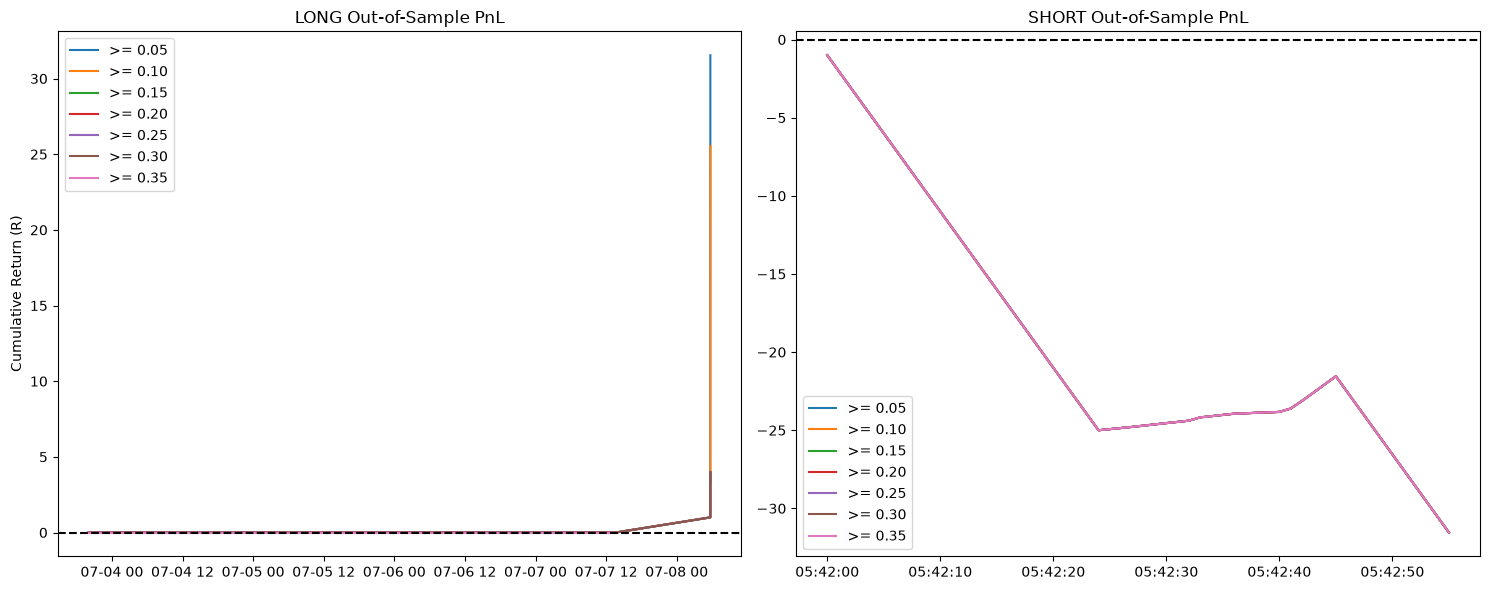

In [2]:
import sys
import os

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

import numpy as np
import pandas as pd
from numpy.lib.stride_tricks import sliding_window_view

from utils.indicators import *
from utils.engine import *

import lightgbm as lgb
from sklearn.metrics import precision_score, recall_score, classification_report
import matplotlib.pyplot as plt

from utils.engine import *

# ============================================================================
# CONFIG
# ============================================================================
LOOKAHEAD_SECONDS    = 240     # how far forward we walk the price path looking for a barrier touch
BARRIER_MULTIPLIER   = 1.0     # profit/stop barrier = multiplier * horizon-scaled vol
RSI_FILTER_COLUMN    = 'rsi_14'
RSI_FILTER_THRESHOLD = 30
EPS                  = 1e-9    # guards against division by zero
BARRIER_CHUNK_SIZE   = 50_000  # rows processed per chunk in the vectorized barrier walk (memory control)

# --- Chronological Validation Settings ---
N_RANDOM_SAMPLES    = 20      # Number of sequential walk-forward folds to test
TEST_BLOCK_SIZE     = 100   # Number of rows per test chunk
EMBARGO_SECONDS      = LOOKAHEAD_SECONDS

# --- 2-Class Binary Label Encoding (INVERTED FOR SHORT STRATEGY) ---
# WIN  = Profit barrier (LOWER) touched FIRST, OR timeout occurred with price < entry
# LOSS = Stop barrier (UPPER) touched FIRST, OR timeout occurred with price >= entry
LABEL_SHORT    = 0
LABEL_LONG     = 1
CLASS_NAMES   = {LABEL_SHORT: 'LOSS', LABEL_LONG: 'WIN'}


# ============================================================================
# STEP 1 — Per-session feature pipeline
# ============================================================================
def load_and_build_state_space(orderbook_path, trades_path, session_id):
    df_orderbook = pd.read_csv(orderbook_path)
    df_trades = pd.read_csv(trades_path)

    df_orderbook['datetime'] = pd.to_datetime(df_orderbook['timestamp'], unit='ms')
    df_trades['datetime'] = pd.to_datetime(df_trades['timestamp'], unit='ms')

    df_orderbook = df_orderbook.set_index('datetime').sort_index()
    df_trades = df_trades.set_index('datetime').sort_index()

    df_orderbook['mid_price'] = (df_orderbook['bid_price'] + df_orderbook['ask_price']) / 2

    df_ob_1m = df_orderbook.resample('1min').agg({
        'mid_price': ['first', 'max', 'min', 'last'],
        'bid_price': 'last',
        'ask_price': 'last',
        'bid_amount': 'sum',
        'ask_amount': 'sum',
    })
    df_ob_1m.columns = ['open', 'high', 'low', 'close', 'bid_price', 'ask_price', 'bid_amount', 'ask_amount']
    df_ob_1m['spread'] = df_ob_1m['ask_price'] - df_ob_1m['bid_price']

    df_trades['buy_vol'] = df_trades['amount'].where(df_trades['side'] == 'buy', 0)
    df_trades['sell_vol'] = df_trades['amount'].where(df_trades['side'] == 'sell', 0)

    df_micro = df_trades.resample('1s').agg({
        'price': 'last',
        'buy_vol': 'sum',
        'sell_vol': 'sum'
    }).ffill()

    df_micro['micro_OFI'] = df_micro['buy_vol'] - df_micro['sell_vol']
    df_micro['micro_CVD'] = df_micro['micro_OFI'].rolling(10).sum()

    df_trades_1m = df_trades.resample('1min').agg({
        'price': ['first', 'max', 'min', 'last', 'count'],
        'amount': 'sum',
        'buy_vol': ['sum', 'max'],
        'sell_vol': ['sum', 'max']
    })
    df_trades_1m.columns = ['open', 'high', 'low', 'close', 'num_trades', 'volume',
                             'agg_buyer', 'largest_buyer', 'agg_seller', 'largest_seller']
    df_trades_1m = df_trades_1m.dropna(subset=['close'])

    df_price_1m = pd.DataFrame({
        'open': df_ob_1m['open'],
        'high': df_ob_1m['high'],
        'low': df_ob_1m['low'],
        'close': df_ob_1m['close'],
        'largest_buyer': df_trades_1m['largest_buyer'] * 100 / (df_trades_1m['volume'] + EPS),
        'largest_seller': df_trades_1m['largest_seller'] * 100 / (df_trades_1m['volume'] + EPS),
        'OFI_LOB': 100 * (df_ob_1m['bid_amount'] - df_ob_1m['ask_amount']) / (df_ob_1m['bid_amount'] + df_ob_1m['ask_amount'] + EPS),
        'OFI_AGG': 100 * (df_trades_1m['agg_buyer'] - df_trades_1m['agg_seller']) / (df_trades_1m['agg_buyer'] + df_trades_1m['agg_seller'] + EPS),
        'CVD_raw': calculate_cvd(df_trades_1m['agg_buyer'], df_trades_1m['agg_seller']),
        'candle_type': abs(df_ob_1m['close'] - df_ob_1m['open']) / (abs(df_ob_1m['high'] - df_ob_1m['low']) + EPS),
        'candle_size': (df_ob_1m['high'] - df_ob_1m['low']) / ((df_ob_1m['high'] - df_ob_1m['low']).rolling(14).mean() + EPS),
    })

    cvd_delta = df_price_1m['CVD_raw'].diff()
    df_price_1m['CVD_z'] = (cvd_delta - cvd_delta.rolling(60).mean()) / (cvd_delta.rolling(60).std() + EPS)
    df_price_1m = df_price_1m.drop(columns=['CVD_raw'])

    price_clean = np.asarray(df_price_1m['close'], dtype=float)
    diffs = np.diff(price_clean)

    def _pad_front(arr, target_len):
        out = np.full(target_len, np.nan)
        out[-len(arr):] = arr
        return out

    df_price_1m['rsi_2'] = _pad_front(get_wilders_rsi(diffs, 2), len(df_price_1m))
    rsi_14_raw = get_wilders_rsi(diffs, 14)
    df_price_1m['rsi_14'] = _pad_front(rsi_14_raw, len(df_price_1m))
    df_price_1m['sma_14'] = _pad_front(sma(rsi_14_raw, 14), len(df_price_1m))

    df_micro_shifted = df_micro.shift(1)
    df_macro_shifted = df_price_1m.shift(1)

    df_state_space = df_micro_shifted.join(df_macro_shifted, how='left').ffill()
    df_state_space = df_state_space.dropna()
    df_state_space['session_id'] = session_id

    return df_state_space


# ============================================================================
# STEP 2 — Build combined state space from all sessions
# ============================================================================

session_0 = load_and_build_state_space(
    "./csv/BTCUSDT_orderbook.csv", "./csv/BTCUSDT_trades.csv", session_id=0
)
session_1 = load_and_build_state_space(
    "./csv/BTCUSDT_orderbook_2.csv", "./csv/BTCUSDT_trades_2.csv", session_id=1
)
session_2 = load_and_build_state_space(
    "./csv/BTCUSDT_orderbook_3.csv", "./csv/BTCUSDT_trades_3.csv", session_id=1
)

df_state_space = pd.concat([session_0, session_1, session_2]).sort_index()

# ============================================================================
# STEP 3 — Barrier labeling (INVERTED FOR SHORT STRATEGY)
# ============================================================================
def _bidirectional_barrier(price, barrier_pct, lookahead, chunk_size=BARRIER_CHUNK_SIZE):
    """
    Calculates unified labels (0 for Short win, 1 for Long win) and the exact 
    exit price for every row so we can calculate dynamic R-Multiples later.
    """
    price = np.asarray(price, dtype=float)
    barrier_pct = np.asarray(barrier_pct, dtype=float)
    n = len(price)

    label = np.full(n, -1, dtype=int)
    exit_price_arr = np.full(n, np.nan)
    is_timeout = np.zeros(n, dtype=bool)
    valid = np.zeros(n, dtype=bool)

    usable_n = n - lookahead 
    if usable_n <= 0:
        return label, exit_price_arr, is_timeout, valid

    for c0 in range(0, usable_n, chunk_size):
        c1 = min(c0 + chunk_size, usable_n)

        p0 = price[c0:c1]
        bp = barrier_pct[c0:c1] 

        # Symmetric absolute boundaries based on your volatility calculation
        upper = p0 * (1.0 + bp)
        lower = p0 * (1.0 - bp)

        window = sliding_window_view(price[c0 + 1: c1 + lookahead], lookahead) 

        hit_upper = window >= upper[:, None]
        hit_lower = window <= lower[:, None]

        has_upper = hit_upper.any(axis=1)
        has_lower = hit_lower.any(axis=1)
        first_upper = np.argmax(hit_upper, axis=1) 
        first_lower = np.argmax(hit_lower, axis=1) 

        # Win conditions for BOTH directions
        long_win = has_upper & (~has_lower | (first_upper < first_lower))
        short_win = has_lower & (~has_upper | (first_lower < first_upper))
        
        # Timeouts resolved strictly by where price ended relative to entry
        timeout_mask = ~(long_win | short_win)
        timeout_long = timeout_mask & (window[:, -1] >= p0) 
        timeout_short = timeout_mask & (window[:, -1] < p0)

        # Assign Labels (1 = Market goes UP, 0 = Market goes DOWN)
        lab = np.full(c1 - c0, -1, dtype=int)
        lab[long_win | timeout_long] = LABEL_LONG
        lab[short_win | timeout_short] = LABEL_SHORT

        # Find exact exit prices for R-Multiple math
        off = np.full(c1 - c0, lookahead - 1, dtype=int) 
        off[long_win] = first_upper[long_win]
        off[short_win] = first_lower[short_win]
        
        # Array of exact price we exited at (either barrier hit or timeout end)
        exit_p = window[np.arange(c1 - c0), off]

        label[c0:c1] = lab
        exit_price_arr[c0:c1] = exit_p
        is_timeout[c0:c1] = timeout_mask
        valid[c0:c1] = ~np.isnan(bp)

    return label, exit_price_arr, is_timeout, valid

def add_barrier_labels(df, lookahead_seconds=LOOKAHEAD_SECONDS, barrier_mult=BARRIER_MULTIPLIER):
    labeled = []
    for _, g in df.groupby('session_id', sort=False):
        g = g.copy()
        ret_std_1s = g['price'].pct_change().rolling(window=100).std()
        
        # Single barrier percentage based on volatility (symmetric)
        g['barrier_pct'] = ret_std_1s * np.sqrt(lookahead_seconds) * barrier_mult

        label, exit_price, is_timeout, valid = _bidirectional_barrier(
            g['price'].values, g['barrier_pct'].values, lookahead_seconds
        )

        g['target'] = label
        g['exit_price'] = exit_price 
        g['is_timeout'] = is_timeout
        g['_valid'] = valid

        g = g[g['_valid']].drop(columns=['_valid'])
        labeled.append(g)

    return pd.concat(labeled)

# Build features and subset to hunting zone
df_state_space = add_barrier_labels(df_state_space)
df_training_zone = df_state_space[df_state_space[RSI_FILTER_COLUMN] < RSI_FILTER_THRESHOLD].copy()

# ============================================================================
# REVISED STEP 4 — Dual R-Multiple Bookkeeping (Apply to Full Dataset)
# ============================================================================
barrier_price_dist = df_state_space['price'] * df_state_space['barrier_pct']

df_state_space['R_LONG'] = (df_state_space['exit_price'] - df_state_space['price']) / (barrier_price_dist + EPS)
df_state_space['R_SHORT'] = (df_state_space['price'] - df_state_space['exit_price']) / (barrier_price_dist + EPS)

df_state_space.loc[~df_state_space['is_timeout'], 'R_LONG'] = np.clip(df_state_space.loc[~df_state_space['is_timeout'], 'R_LONG'], -1.0, 1.0)
df_state_space.loc[~df_state_space['is_timeout'], 'R_SHORT'] = np.clip(df_state_space.loc[~df_state_space['is_timeout'], 'R_SHORT'], -1.0, 1.0)


# ============================================================================
# REVISED STEP 5 — Features and Target Setup (Full Dataset)
# ============================================================================
drop_cols = ['target', 'price', 'open', 'high', 'low', 'close', 'barrier_pct', 
             'session_id', 'exit_price', 'is_timeout', 'R_LONG', 'R_SHORT']
features = [c for c in df_state_space.columns if c not in drop_cols]

# Notice we use df_state_space here, NOT df_training_zone
X = df_state_space[features]
y = df_state_space['target']


# ============================================================================
# REVISED STEP 6 — Walk-Forward Execution
# ============================================================================
def PurgedTimeSeriesSplit(index, n_samples, block_size, horizon_seconds, embargo_seconds=0):
    n = len(index)
    horizon = pd.Timedelta(seconds=horizon_seconds)
    min_initial_train = int(n * 0.35)
    available_test_run = n - min_initial_train - block_size

    if available_test_run <= 0:
        raise ValueError("The dataset length is too narrow for this test configuration block size.")

    step_intervals = available_test_run // n_samples

    for fold in range(n_samples):
        start_idx = min_initial_train + (fold * step_intervals)
        test_idx = np.arange(start_idx, start_idx + block_size)
        test_start_time = index[test_idx[0]]

        possible_train_idx = np.arange(0, start_idx)
        train_times = index[possible_train_idx]

        purge_mask = (train_times + horizon >= test_start_time)
        train_idx = possible_train_idx[~purge_mask]

        n_purged = len(possible_train_idx) - len(train_idx)
        yield train_idx, test_idx, n_purged


print(f"\n--- Starting Bidirectional Validation Folds ---")

thresholds = np.arange(0.05, 0.40, 0.05)

long_metrics = {t: {'trades': 0, 'wins': 0, 'r_returns': []} for t in thresholds}
short_metrics = {t: {'trades': 0, 'wins': 0, 'r_returns': []} for t in thresholds}
long_trade_log = {t: [] for t in thresholds}
short_trade_log = {t: [] for t in thresholds}

# (Replace 'PurgedTimeSeriesSplit' with the actual class name inside your utils.engine)
splitter = PurgedTimeSeriesSplit(
    index=X.index,                      # FIX 1: Pass the actual datetime index, not the whole DataFrame
    n_samples=N_RANDOM_SAMPLES, 
    block_size=TEST_BLOCK_SIZE,         # FIX 2: Corrected argument name to match the function definition
    horizon_seconds=LOOKAHEAD_SECONDS,  # FIX 3: Added the missing required argument
    embargo_seconds=EMBARGO_SECONDS
)

thresholds = np.arange(0.05, 0.40, 0.05)

for fold, (train_idx, test_idx, n_purged) in enumerate(splitter, start=1):
    # 1. Split the raw, continuous data first
    X_train_raw, X_test_raw = X.iloc[train_idx], X.iloc[test_idx]
    y_train_raw, y_test_raw = y.iloc[train_idx], y.iloc[test_idx]

    # 2. Apply the RSI filter ON THE SPLITS to create the "Hunting Zone"
    train_mask = X_train_raw[RSI_FILTER_COLUMN] < RSI_FILTER_THRESHOLD
    test_mask = X_test_raw[RSI_FILTER_COLUMN] < RSI_FILTER_THRESHOLD

    X_train = X_train_raw[train_mask]
    y_train = y_train_raw[train_mask]
    X_test = X_test_raw[test_mask]
    y_test = y_test_raw[test_mask]

    # 3. Guard rails: skip if the filter wiped out the data for this specific fold
    if len(X_train) == 0 or y_train.nunique() < 2:
        print(f"Fold {fold} Skipped: Insufficient data after RSI filter. Rows: {len(X_train)}, Classes: {y_train.nunique()}")
        continue

    # Train LightGBM
    clf = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, max_depth=5, 
                             class_weight='balanced', random_state=42, n_jobs=-1, verbose=-1)
    clf.fit(X_train, y_train)

    long_idx = list(clf.classes_).index(LABEL_LONG)
    short_idx = list(clf.classes_).index(LABEL_SHORT)
    
    # If the test set has zero rows after filtering, skip prediction
    if len(X_test) == 0:
        continue

    p_long = clf.predict_proba(X_test)[:, long_idx]
    p_short = clf.predict_proba(X_test)[:, short_idx]
    
    for t in thresholds:
        # LONGS
        long_signals = (p_long >= t)
        if long_signals.sum() > 0:
            traded_idx = X_test.index[long_signals]
            actual_targets = y_test.loc[traded_idx]
            actual_r = df_state_space.loc[traded_idx, 'R_LONG'] # Use full dataframe
            
            long_metrics[t]['trades'] += len(traded_idx)
            long_metrics[t]['wins'] += (actual_targets == LABEL_LONG).sum()
            long_metrics[t]['r_returns'].extend(actual_r.tolist())
            long_trade_log[t].extend(zip(traded_idx, actual_r.values))

        # SHORTS
        short_signals = (p_short >= t)
        if short_signals.sum() > 0:
            traded_idx = X_test.index[short_signals]
            actual_targets = y_test.loc[traded_idx]
            actual_r = df_state_space.loc[traded_idx, 'R_SHORT'] # Use full dataframe
            
            short_metrics[t]['trades'] += len(traded_idx)
            short_metrics[t]['wins'] += (actual_targets == LABEL_SHORT).sum()
            short_metrics[t]['r_returns'].extend(actual_r.tolist())
            short_trade_log[t].extend(zip(traded_idx, actual_r.values))

    print(f"Fold {fold} Complete | Mean P(Long): {p_long.mean():.4f} | Max P(Long): {p_long.max():.4f}")

# ============================================================================
# STEP 7 — Generate the TWO SEPARATE REPORTS
# ============================================================================
def generate_report(metrics_dict, direction_name):
    print(f"\n" + "="*80)
    print(f" {direction_name.upper()} STRATEGY REPORT (Precision == Win Rate)")
    print("="*80)
    print(f"{'Confidence':<12} | {'Trades':<8} | {'Win Rate':<10} | {'Avg RR per Trade':<18} | {'Total PnL'}")
    print("-" * 80)
    
    for t in thresholds:
        stats = metrics_dict[t]
        trades = stats['trades']
        if trades == 0:
            print(f"P({direction_name}) >= {t:.2f} | {0:<8} | {'n/a':<10} | {'n/a':<18} | 0.00R")
            continue
            
        win_rate = stats['wins'] / trades
        r_arr = np.array(stats['r_returns'])
        avg_r = r_arr.mean()
        std_r = r_arr.std()
        total_r = r_arr.sum()
        
        print(f"P({direction_name}) >= {t:.2f} | {trades:<8} | {win_rate:>6.2%}   | {avg_r:>5.2f}R ± {std_r:<5.2f}R   | {total_r:+.2f}R")

# Output the separate reports
generate_report(long_metrics, "Long")
generate_report(short_metrics, "Short")

# ============================================================================
# STEP 8 — Combined PnL Charting
# ============================================================================
plt.figure(figsize=(15, 6))

# Subplot 1: Long PnL
plt.subplot(1, 2, 1)
for i, t in enumerate(thresholds):
    if len(long_trade_log[t]) > 0:
        df_log = pd.DataFrame(long_trade_log[t], columns=['time', 'r']).sort_values('time')
        plt.plot(df_log['time'], df_log['r'].cumsum(), label=f'>= {t:.2f}')
plt.axhline(0, color='black', linestyle='--')
plt.title('LONG Out-of-Sample PnL')
plt.ylabel('Cumulative Return (R)')
plt.legend()

# Subplot 2: Short PnL
plt.subplot(1, 2, 2)
for i, t in enumerate(thresholds):
    if len(short_trade_log[t]) > 0:
        df_log = pd.DataFrame(short_trade_log[t], columns=['time', 'r']).sort_values('time')
        plt.plot(df_log['time'], df_log['r'].cumsum(), label=f'>= {t:.2f}')
plt.axhline(0, color='black', linestyle='--')
plt.title('SHORT Out-of-Sample PnL')
plt.legend()

plt.tight_layout()
plt.savefig('bidirectional_pnl.png', dpi=150)
print("\nSaved bidirectional dual-chart to bidirectional_pnl.png")



# Linear Split 80/20
Before its following chronological split system.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import lightgbm as lgb
from matplotlib.gridspec import GridSpec

# ============================================================================
# CONFIG FOR BACKTEST
# ============================================================================
CONFIDENCE_THRESHOLD = 0.85  # Model probability required to fire a trade
STRATEGY_TYPE        = 'SHORT' # Options: 'LONG' or 'SHORT' (Fade the long model safely)
FEE_BPS              = 0.0     # Assumed execution fee in basis points (e.g., Binance taker)
TRAIN_TEST_SPLIT     = 0.80    # 80% train, 20% chronological test

fee_pct = FEE_BPS / 10000

# ============================================================================
# STEP 1 — Chronological Split with Boundary Purging
# ============================================================================
df_bt = df_training_zone.sort_index().copy()

split_idx = int(len(df_bt) * TRAIN_TEST_SPLIT)
test_data = df_bt.iloc[split_idx:].copy()

# FIXED: Purge the end of the training data block to eliminate edge leakage into test data
horizon = pd.Timedelta(seconds=LOOKAHEAD_SECONDS)
train_data_raw = df_bt.iloc[:split_idx]
train_data = train_data_raw[train_data_raw.index + horizon < test_data.index[0]]

X_train_bt = train_data[features]
y_train_bt = train_data['target']
X_test_bt = test_data[features]
y_test_bt = test_data['target']

# ============================================================================
# STEP 2 — Train Model
# ============================================================================
neg_pos_ratio = sum(y_train_bt == 0) / max(sum(y_train_bt == 1), 1)

clf_bt = lgb.LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    num_leaves=31,
    scale_pos_weight=neg_pos_ratio,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

print(f"Training on {len(X_train_bt)} rows (Purged), Testing on {len(X_test_bt)} rows...")
clf_bt.fit(X_train_bt, y_train_bt)

# ============================================================================
# STEP 3 — Generate Signals & Path-Dependent Vectorized PnL Calculation
# ============================================================================
# 1. Generate the probability and signal first
test_data['prob'] = clf_bt.predict_proba(X_test_bt)[:, 1]
test_data['signal'] = (test_data['prob'] >= CONFIDENCE_THRESHOLD).astype(int)

# 2. Define the mask AFTER signal is created
traded_mask = test_data['signal'] == 1

# 3. Define exact barrier paths
hit_upside    = (test_data['mfe'] >= test_data['profit_barrier']) & (test_data['mae'] < test_data['stop_barrier'])
hit_downside  = (test_data['mae'] >= test_data['stop_barrier']) & (test_data['mfe'] < test_data['profit_barrier'])
both_breached = (test_data['mfe'] >= test_data['profit_barrier']) & (test_data['mae'] >= test_data['stop_barrier'])
timed_out     = (~hit_upside) & (~hit_downside) & (~both_breached)

# 4. Initialize trade_return
test_data['trade_return'] = 0.0

if STRATEGY_TYPE == 'LONG':
    test_data.loc[traded_mask & hit_upside, 'trade_return'] = test_data['profit_barrier'] - fee_pct
    test_data.loc[traded_mask & (hit_downside | both_breached), 'trade_return'] = -test_data['stop_barrier'] - fee_pct
    test_data.loc[traded_mask & timed_out, 'trade_return'] = test_data['terminal_ret'] - fee_pct

elif STRATEGY_TYPE == 'SHORT':
    test_data.loc[traded_mask & hit_downside, 'trade_return'] = test_data['profit_barrier'] - fee_pct
    test_data.loc[traded_mask & (hit_upside | both_breached), 'trade_return'] = -test_data['stop_barrier'] - fee_pct
    test_data.loc[traded_mask & timed_out, 'trade_return'] = -test_data['terminal_ret'] - fee_pct

# 5. Calculate tracking equity profile
test_data['equity_curve'] = test_data['trade_return'].cumsum()

# ============================================================================
# STEP 4 — Performance Metrics
# ============================================================================
total_trades = traded_mask.sum()

if total_trades > 0:
    # A trade won if its return after fees is positive
    won_mask = traded_mask & (test_data['trade_return'] > 0)
    lost_mask = traded_mask & (test_data['trade_return'] <= 0)
    
    winning_trades = won_mask.sum()
    win_rate = winning_trades / total_trades
    
    running_max = test_data['equity_curve'].cummax()
    drawdown = test_data['equity_curve'] - running_max
    max_drawdown = drawdown.min()
    
    daily_returns = test_data['trade_return'].resample('D').sum()
    daily_std = daily_returns.std()
    
    if daily_std > 0:
        sharpe_ratio = (daily_returns.mean() / daily_std) * np.sqrt(365)
    else:
        sharpe_ratio = 0.0

    total_return_pct = test_data['equity_curve'].iloc[-1]
else:
    win_rate = 0.0
    max_drawdown = 0.0
    sharpe_ratio = 0.0
    total_return_pct = 0.0
    drawdown = pd.Series(0, index=test_data.index)

print("\n" + "="*50)
print(f" 📈 STRATEGY PERFORMANCE SUMMARY ({STRATEGY_TYPE} OUT OF SAMPLE)")
print("="*50)
print(f"Total Trades Taken : {total_trades}")
print(f"Win Rate           : {win_rate:.2%}")
print(f"Total Net Return   : {total_return_pct:.2%} (Fixed size)")
print(f"Max Drawdown       : {max_drawdown:.2%}")
print(f"Daily Sharpe Ratio : {sharpe_ratio:.2f}")
print("="*50)

# ============================================================================
# STEP 5 — Visualization
# ============================================================================
if total_trades > 0:
    fig = plt.figure(figsize=(14, 8))
    gs = GridSpec(3, 1, height_ratios=[2, 1, 1], hspace=0.3)

    # 1. Equity Curve
    ax1 = fig.add_subplot(gs[0])
    ax1.plot(test_data.index, test_data['equity_curve'] * 100, color='blue', linewidth=1.5)
    ax1.set_title(f"Simulated Out-of-Sample Equity Curve ({STRATEGY_TYPE} - Net of Fees)", fontsize=14, fontweight='bold')
    ax1.set_ylabel("Cumulative Return (%)", fontsize=12)
    ax1.grid(True, alpha=0.3)

    # 2. Drawdown Chart
    ax2 = fig.add_subplot(gs[1], sharex=ax1)
    ax2.fill_between(test_data.index, drawdown * 100, 0, color='red', alpha=0.4)
    ax2.plot(test_data.index, drawdown * 100, color='red', linewidth=1)
    ax2.set_title("Underwater Chart (Drawdown)", fontsize=12)
    ax2.set_ylabel("Drawdown (%)", fontsize=12)
    ax2.grid(True, alpha=0.3)

    # 3. Model Probabilities & Trade Triggers
    ax3 = fig.add_subplot(gs[2], sharex=ax1)
    ax3.scatter(test_data[won_mask].index, test_data[won_mask]['prob'], color='green', s=10, label='Won Trade', alpha=0.7)
    ax3.scatter(test_data[lost_mask].index, test_data[lost_mask]['prob'], color='red', s=10, label='Lost Trade', alpha=0.7)
    ax3.axhline(CONFIDENCE_THRESHOLD, color='black', linestyle='--', linewidth=1, label=f'Threshold ({CONFIDENCE_THRESHOLD})')
    ax3.set_title("Model Confidence & Trade Executions", fontsize=12)
    ax3.set_ylabel("Probability", fontsize=12)
    ax3.set_ylim(0, 1)
    ax3.legend(loc='lower left', ncol=3)
    ax3.grid(True, alpha=0.3)

    plt.show()
else:
    print("No trades were executed. Try adjusting your CONFIDENCE_THRESHOLD.")

# Calculate Average Risk per Trade (the average percentage distance to the stop)
# Note: This looks at the 'stop_barrier' for trades that were triggered
if total_trades > 0:
    # Filter the stop_barrier values only for rows where a trade was actually taken
    risks_taken = test_data.loc[traded_mask, 'stop_barrier']
    avg_risk_per_trade = risks_taken.mean()
    
    # Calculate realized risk (what was actually lost on losing trades)
    avg_loss_on_losers = test_data.loc[lost_mask, 'trade_return'].abs().mean()
    
    print("\n" + "="*50)
    print(" 🛡️ RISK METRICS")
    print("="*50)
    print(f"Avg Stop Barrier (Designed Risk) : {avg_risk_per_trade:.2%}")
    print(f"Avg Actual Loss (on losers)      : {avg_loss_on_losers:.2%}")
    print(f"Risk-Reward Ratio (Avg)          : { (test_data.loc[won_mask, 'trade_return'].mean() / avg_loss_on_losers):.2f}")
    print("="*50)

# Check exactly what is happening to your trades
print(f"Profit Hits: { (traded_mask & hit_upside).sum() }")
print(f"Stop Hits:   { (traded_mask & hit_downside).sum() }")
print(f"Time Outs:   { (traded_mask & timed_out).sum() }")

Training on 33936 rows (Purged), Testing on 8544 rows...


KeyError: 'mfe'